# Análise Exploratória de Dados — Gapminder (1952–2007)

Este notebook apresenta a análise exploratória do dataset público **Gapminder** (142 países, 5 continentes, recortes quinquenais de 1952 a 2007), consumindo diretamente os módulos reutilizáveis em `src/` para responder às 5 perguntas definidas no `PRD.md`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data_cleaning import add_derived_metrics, clean_gapminder, generate_quality_report
from src.data_loader import load_raw_gapminder
from src.visualizations import (
    plot_gdp_vs_life_expectancy_2007,
    plot_historical_drops_outliers,
    plot_life_expectancy_distribution_comparison,
    plot_life_expectancy_evolution,
    plot_top_life_expectancy_gains,
)

raw_df = load_raw_gapminder(download_if_missing=False)
df = add_derived_metrics(clean_gapminder(raw_df))
quality = generate_quality_report(df)
print('Resumo de qualidade:', quality)
df.head()

Resumo de qualidade: {'rows': 1704, 'countries': 142, 'continents': 5, 'year_min': 1952, 'year_max': 2007, 'duplicate_country_year': 0, 'nulls_core_columns': {'country': 0, 'continent': 0, 'year': 0, 'lifeExp': 0, 'pop': 0, 'gdpPercap': 0}}


,country,continent,year,lifeExp,pop,gdpPercap,gdp_total,decade,lifeExp_diff_5y,gdpPercap_pct_change_5y
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,6.567086e+09,1950,NaN,NaN
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,7.585449e+09,1950,1.531,5.312459
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,8.758856e+09,1960,1.665,3.928557
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,9.648014e+09,1960,2.023,-1.981427
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,9.678553e+09,1970,2.068,-11.506381


## Pergunta 1 — Evolução Temporal da Expectativa de Vida (1952–2007)

**Como evoluiu a expectativa de vida global e por continente entre 1952 e 2007?**

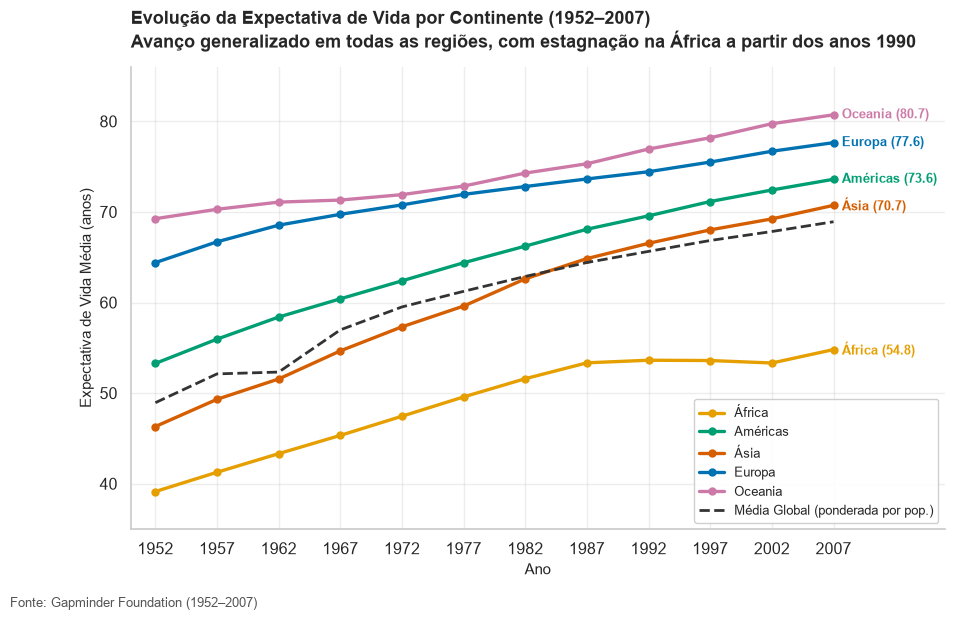

In [2]:
fig1 = plot_life_expectancy_evolution(df)
plt.show()
plt.close(fig1)

**Interpretação:** Todas as regiões apresentaram ganhos expressivos em 55 anos. A Ásia e as Américas protagonizaram a maior convergência em direção à Europa e à Oceania, enquanto a África desacelerou e estagnou nos anos 1990 em decorrência de crises sanitárias e conflitos regionais.

## Pergunta 2 — Relação entre PIB per Capita e Expectativa de Vida

**Qual é a relação entre PIB per capita e expectativa de vida em escala logarítmica?**

Correlação Pearson (linear, 2007): 0.679
Correlação Pearson (log10 PIB, 2007): 0.809
Correlação Spearman (monotônica, 2007): 0.857


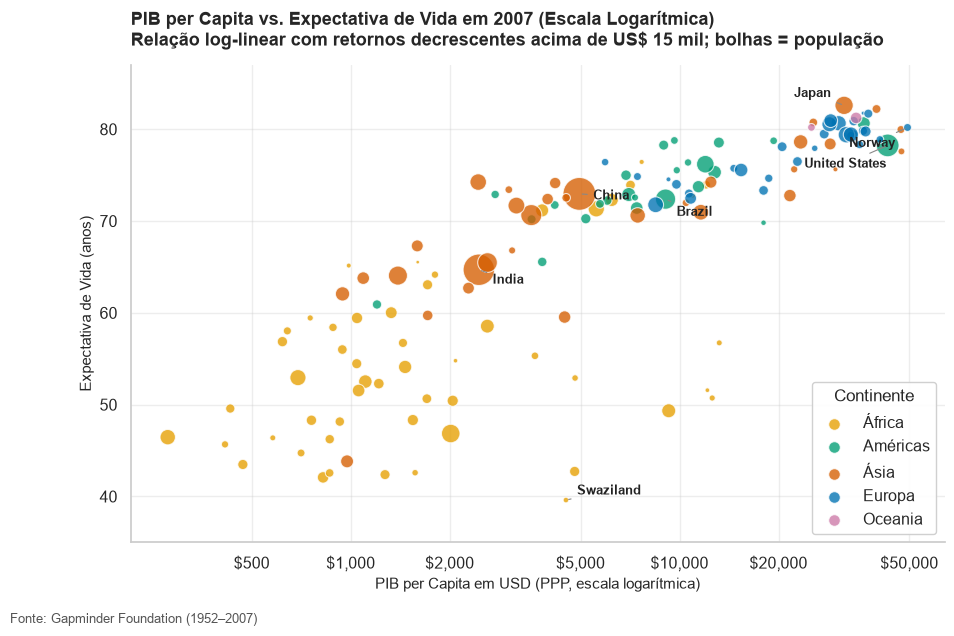

In [3]:
import numpy as np
df_2007 = df[df['year'] == 2007]
pearson_linear = df_2007['gdpPercap'].corr(df_2007['lifeExp'], method='pearson')
pearson_log = np.log10(df_2007['gdpPercap']).corr(df_2007['lifeExp'], method='pearson')
spearman_corr = df_2007['gdpPercap'].rank().corr(df_2007['lifeExp'].rank(), method='pearson')
print(f'Correlação Pearson (linear, 2007): {pearson_linear:.3f}')
print(f'Correlação Pearson (log10 PIB, 2007): {pearson_log:.3f}')
print(f'Correlação Spearman (monotônica, 2007): {spearman_corr:.3f}')

fig2 = plot_gdp_vs_life_expectancy_2007(df)
plt.show()
plt.close(fig2)

**Interpretação:** A relação é fortemente monotônica (Spearman ~0,86) e não-linear: países de baixa renda obtêm ganhos muito altos de longevidade a cada aumento de renda (saneamento, vacinação, atenção primária), enquanto acima de US$ 15.000 per capita os retornos marginais em expectativa de vida se achatam.

## Pergunta 3 — Desigualdade Intra-Continental (1952 vs. 2007)

**Como variou a dispersão da expectativa de vida dentro de cada continente?**

mean  median   std    min    max
continent year                                   
Africa    1952  39.14   38.83  5.15  30.00  52.72
          2007  54.81   52.93  9.63  39.61  76.44
Americas  1952  53.28   54.74  9.33  37.58  68.75
          2007  73.61   72.90  4.44  60.92  80.65
Asia      1952  46.31   44.87  9.29  28.80  65.39
          2007  70.73   72.40  7.96  43.83  82.60
Europe    1952  64.41   65.90  6.36  43.58  72.67
          2007  77.65   78.61  2.98  71.78  81.76
Oceania   1952  69.26   69.26  0.19  69.12  69.39
          2007  80.72   80.72  0.73  80.20  81.24

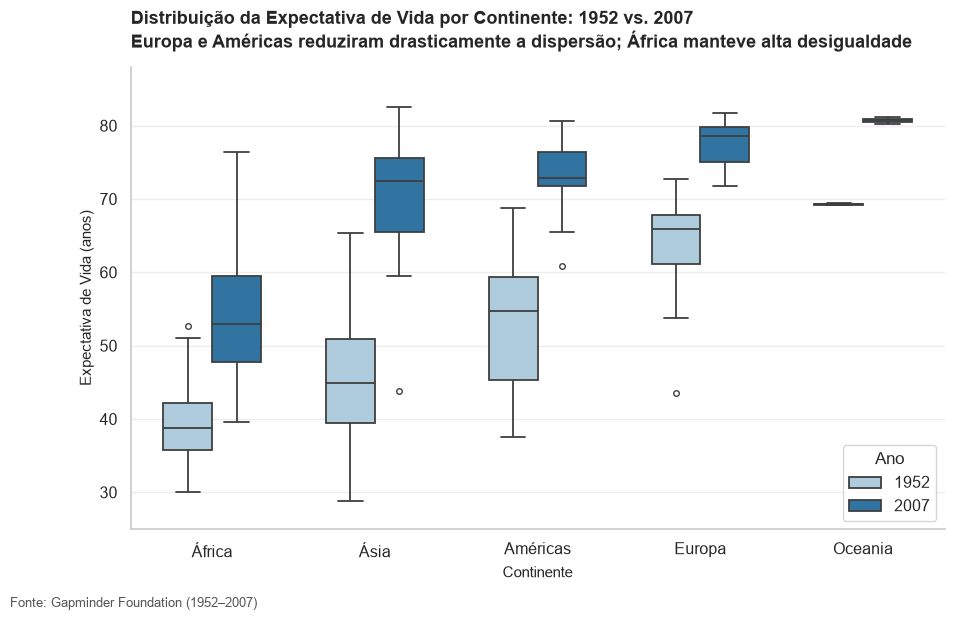

In [4]:
dispersion = (
    df[df['year'].isin([1952, 2007])]
    .groupby(['continent', 'year'])['lifeExp']
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .round(2)
)
display(dispersion)

fig3 = plot_life_expectancy_distribution_comparison(df)
plt.show()
plt.close(fig3)

**Interpretação:** Europa e Américas não apenas elevaram suas medianas, como também comprimiram drasticamente o desvio-padrão entre seus países. Na África, embora a mediana tenha subido, a amplitude interquartil aumentou, evidenciando trajetórias divergentes entre o Norte da África e a África Subsaariana.

## Pergunta 4 — Maiores Ganhos Absolutos em Expectativa de Vida

**Quais países registraram o maior ganho absoluto entre 1952 e 2007?**

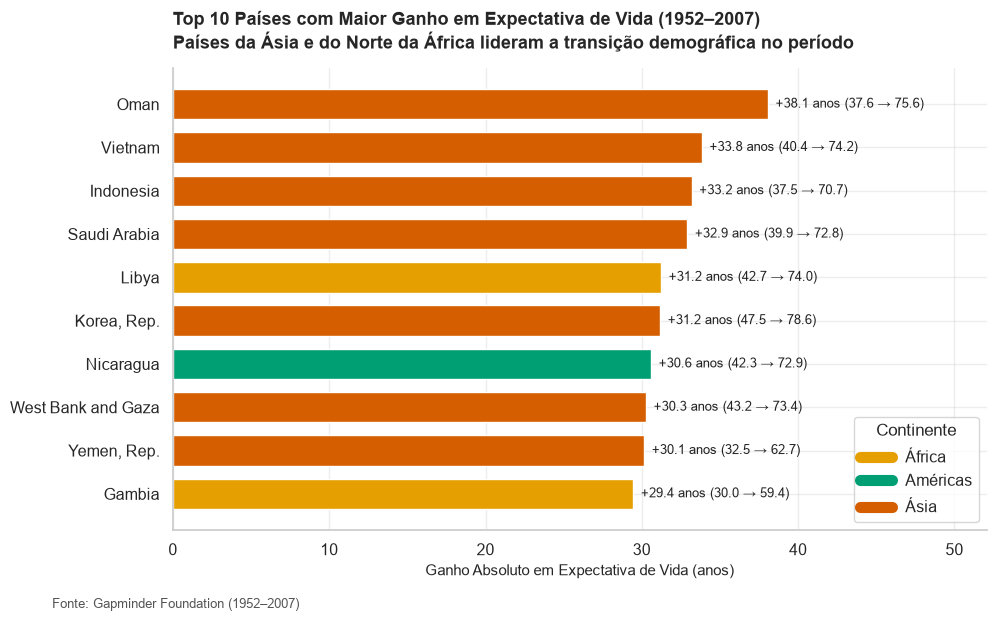

In [5]:
fig4 = plot_top_life_expectancy_gains(df, top_n=10)
plt.show()
plt.close(fig4)

**Interpretação:** Países da Ásia (como Omã, Vietnã, Indonésia, Arábia Saudita e Coreia do Sul) e do Norte da África (Líbia, Tunísia, Egito) lideram os maiores saltos absolutos, ultrapassando +30 anos de ganho em expectativa de vida em pouco mais de meio século.

## Pergunta 5 — Anomalias e Quedas Abruptas na Série Histórica

**Quais países sofreram as quedas mais severas entre recortes quinquenais consecutivos?**

,country,continent,year,lifeExp,lifeExp_diff_5y
1292,Rwanda,Africa,1992,23.59900,-20.4210
1701,Zimbabwe,Africa,1997,46.80900,-13.5680
886,Lesotho,Africa,2002,44.59300,-10.9650
1462,Swaziland,Africa,2002,43.86900,-10.4200
165,Botswana,Africa,1997,52.55600,-10.1890
221,Cambodia,Asia,1977,31.22000,-9.0970
1066,Namibia,Africa,2002,51.47900,-7.4300
1414,South Africa,Africa,2002,53.36500,-6.8710
1702,Zimbabwe,Africa,2002,39.98900,-6.8200
290,China,Asia,1962,44.50136,-6.0476


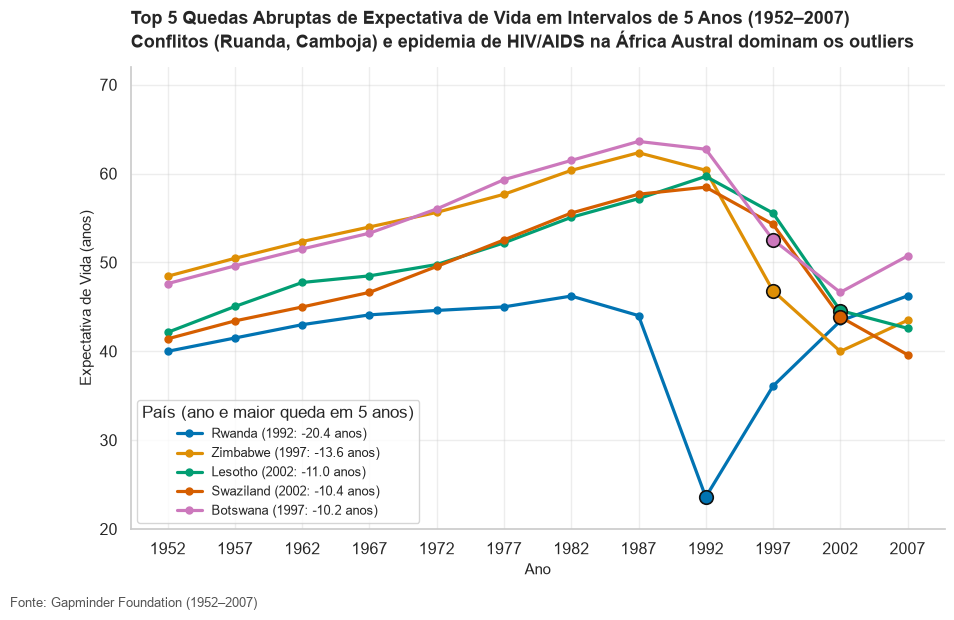

In [6]:
worst = (
    df.dropna(subset=['lifeExp_diff_5y'])
    .sort_values('lifeExp_diff_5y')
    [['country', 'continent', 'year', 'lifeExp', 'lifeExp_diff_5y']]
    .head(10)
)
display(worst)

fig5 = plot_historical_drops_outliers(df, top_n=5)
plt.show()
plt.close(fig5)

**Interpretação:** Os maiores outliers negativos refletem choques históricos documentados: o genocídio em Ruanda (queda de mais de 20 anos registrada no recorte de 1992), o regime do Khmer Vermelho no Camboja (1977) e o impacto severo da epidemia de HIV/AIDS na África Austral (Zimbábue, Botsuana e Suazilândia entre 1997 e 2002).